# 02 · Linearization and discretization

> **In short:** MPC solves a quadratic program, so the nonlinear model is linearized around a nominal trajectory: $x_{k+1}\approx A_kx_k+B_ku_k+C_k$. The package adds a second-order term to $B_k$ so a pitch command already moves the velocity within one step.
>
> **Runtime:** a few seconds · **Read alongside:** [Theory 08 · Linearization](../1.Docs/Theory/08_Linearization.md) · [Theory 09 · Discretization](../1.Docs/Theory/09_Discretization.md)

**You will:**

- build $A_k, B_k, C_k$ with `QuadrotorDynamics.linearize`
- see why the first-order $B_k$ is blind to attitude commands at hover
- measure the linearization error and confirm it is $O(\delta x^2)$

## The discrete affine model

$$A_k=I+\Delta t\,\frac{\partial f}{\partial x},\qquad
B_k=\Delta t\,\frac{\partial f}{\partial u}+\frac{\Delta t^2}{2}\,\frac{\partial f}{\partial x}\frac{\partial f}{\partial u},\qquad
C_k=f_d(\bar x,\bar u)-A_k\bar x-B_k\bar u$$

$C_k$ makes the affine model exact at the expansion point $(\bar x,\bar u)$.

In [1]:
from nbsetup import *

In [2]:
from quadrotor_mpc.control.ccmpc.dynamics import QuadrotorDynamics

dynamics = QuadrotorDynamics.from_config(str(CONFIG / "controller.yaml"))
dt = 0.06
x_bar, u_bar = np.zeros(9), np.zeros(4)
A, B, C = dynamics.linearize(x_bar, u_bar, dt)
A_cont = dynamics.jacobian_state(x_bar, u_bar)
B_cont = dynamics.jacobian_control(x_bar, u_bar)
B_first_order = dt * B_cont

print("dv_x / d theta_c  first-order :", B_first_order[3, 1])
print("dv_x / d theta_c  second-order:", B[3, 1])
print("expected g dt^2/2 k_theta/tau :", dynamics.g * dt**2 / 2 * dynamics.k_theta / dynamics.tau_theta)

dv_x / d theta_c  first-order : 0.0
dv_x / d theta_c  second-order: 0.05350909090910875
expected g dt^2/2 k_theta/tau : 0.05350909090909091


At hover the first-order input matrix says a pitch command has **no** effect on velocity during the
step, because the command first has to tilt the vehicle. An MPC built on it would see attitude
commands as free and over-react. The second-order term captures the cascade
$\theta_c\rightarrow\theta\rightarrow v_x$ within one step.

## Accuracy of the affine model

Two approximations are stacked here:

1. **Linearization** (Taylor expansion around $\bar x$): error $O(\delta x^2)$.
2. **Discretization**: $A_k=I+\Delta t\,\partial f/\partial x$ is a first-order (Euler) transition
   matrix, while the plant integrates with RK4. That mismatch is $O(\Delta t^2)$ per step and grows
   *linearly* with $\delta x$.

The plot separates them by comparing the package matrix with the exact Jacobian of the RK4 step.

error at the expansion point: 0.0


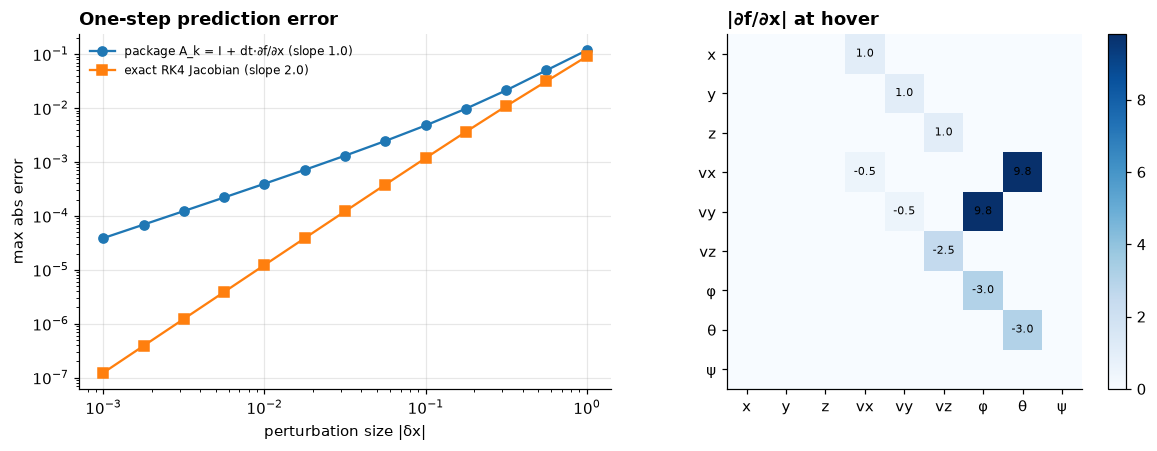

package matrix: error ≈ 0.039·|δx| for small δx (discretization)


In [3]:
x_next = dynamics.discrete(x_bar, u_bar, dt)
print("error at the expansion point:", np.abs(A @ x_bar + B @ u_bar + C - x_next).max())

# Exact Jacobian of the discrete RK4 step (central differences) for comparison.
eps = 1e-6
A_exact = np.column_stack([
    (dynamics.discrete(x_bar + eps * e, u_bar, dt) - dynamics.discrete(x_bar - eps * e, u_bar, dt)) / (2 * eps)
    for e in np.eye(9)
])

rng = np.random.default_rng(0)
direction = rng.normal(size=9)
direction /= np.linalg.norm(direction)
sizes = np.logspace(-3, 0, 13)
err_package, err_exact = [], []
for size in sizes:
    x = x_bar + size * direction
    true_next = dynamics.discrete(x, u_bar, dt)
    err_package.append(np.abs(true_next - (A @ x + B @ u_bar + C)).max())
    err_exact.append(np.abs(true_next - (x_next + A_exact @ (x - x_bar))).max())
slope_package = np.polyfit(np.log(sizes[:6]), np.log(err_package[:6]), 1)[0]
slope_exact = np.polyfit(np.log(sizes[:6]), np.log(err_exact[:6]), 1)[0]

fig, (ax_err, ax_jac) = plt.subplots(1, 2, figsize=(11, 4.2))
ax_err.loglog(sizes, err_package, "o-", label=f"package A_k = I + dt·∂f/∂x (slope {slope_package:.1f})")
ax_err.loglog(sizes, err_exact, "s-", label=f"exact RK4 Jacobian (slope {slope_exact:.1f})")
ax_err.set(title="One-step prediction error", xlabel="perturbation size |δx|", ylabel="max abs error")
ax_err.legend(fontsize=8)
labels = ["x", "y", "z", "vx", "vy", "vz", "φ", "θ", "ψ"]
image = ax_jac.imshow(np.abs(A_cont), cmap="Blues")
ax_jac.set_xticks(range(9), labels)
ax_jac.set_yticks(range(9), labels)
ax_jac.grid(False)
ax_jac.set_title("|∂f/∂x| at hover")
for i in range(9):
    for j in range(9):
        if abs(A_cont[i, j]) > 1e-6:
            ax_jac.text(j, i, f"{A_cont[i, j]:.1f}", ha="center", va="center", fontsize=7)
plt.colorbar(image, ax=ax_jac)
plt.tight_layout()
plt.show()
print(f"package matrix: error ≈ {err_package[0] / sizes[0]:.3f}·|δx| for small δx (discretization)")
assert 0.8 < slope_package < 1.2 and 1.7 < slope_exact < 2.3

## Takeaways

- The QP sees the dynamics only through $(A_k, B_k, C_k)$; their accuracy bounds how far the plan
  can trust the model.
- With $\Delta t=0.06$ s the Euler transition matrix costs about 4 % of $|\delta x|$ per step. The
  controller accepts this for speed: it re-linearizes around every new guess (next notebook) and the
  closed loop corrects the rest.

---

**Previous:** [01_ode_dynamics.ipynb](01_ode_dynamics.ipynb) · **Next:** [03_ode_mpc_and_impc.ipynb](03_ode_mpc_and_impc.ipynb)